In [1]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
RAW = Path(os.environ.get('ASTRO320W_DATA', '/Users/gracedavis/2026-10-19_before_submission_cleanup'))
BIAS = Path(os.environ.get('ASTRO320W_BIAS', '/Users/gracedavis/ASTRO 320W/04_Data/A/Bias_Frames'))


In [2]:
from pathlib import Path
import csv,json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.ndimage import gaussian_filter, maximum_filter
root=RAW
out=OUT
files=sorted((root/'EXERCISE C-2/Ogma calibrated').glob('*.fits'))
# Supplementary repeatability check of an unsaturated field star.
x0,y0=221.,1237.
measure=[]
for f in files:
 d,h=fits.getdata(f,header=True);d=d.astype(float)
 x,y=x0,y0
 for _ in range(4):
  ix,iy=int(round(x)),int(round(y));sub=d[iy-9:iy+10,ix-9:ix+10]
  yy,xx=np.mgrid[iy-9:iy+10,ix-9:ix+10]
  w=np.maximum(sub-np.median(sub),0);x=float((xx*w).sum()/w.sum());y=float((yy*w).sum()/w.sum())
 ix,iy=int(round(x)),int(round(y));sub=d[iy-68:iy+69,ix-68:ix+69]
 yy,xx=np.mgrid[iy-68:iy+69,ix-68:ix+69];rr=np.hypot(xx-x,yy-y)
 ap=rr<=17;ann=(rr>=34)&(rr<=67)
 sky=np.median(sub[ann]);counts=float((sub[ap]-sky).sum());t=h['EXPTIME']
 sigma_b=1.4826*np.median(np.abs(sub[ann]-sky))
 n_ap=ap.sum();n_ann=ann.sum();gain=1.290
 error=np.sqrt(max(counts,0)/gain+n_ap*sigma_b**2+n_ap**2*np.pi*sigma_b**2/(2*n_ann))
 peak=float(np.max(d[iy-8:iy+9,ix-8:ix+9]))
 measure.append([f.name,x,y,t,counts,counts/t,peak,error/t])
a=np.array([v[5] for v in measure]);mean=a.mean();sd=a.std(ddof=1);pct=100*sd/mean
print('unsaturated field-star result:',mean,sd,pct,'peak range',min(v[6] for v in measure),max(v[6] for v in measure))
with (out/'unsaturated_field_star.csv').open('w') as f:
 w=csv.writer(f);w.writerow(['File','x_array_pix','y_array_pix','Exposure_s','Net_counts_DN','Rate_DN_s','Peak_DN','Approx_rate_error_DN_s']);w.writerows(measure)
(out/'supplementary_repeatability_summary.json').write_text(json.dumps({'mean_rate':mean,'sample_sd_rate':sd,'scatter_percent':pct,'first_xy':[measure[0][1],measure[0][2]],'min_peak':min(v[6] for v in measure),'max_peak':max(v[6] for v in measure),'mean_formal_percent':float(np.mean([100*v[7]/v[5] for v in measure]))},indent=2))
fig,axs=plt.subplots(1,2,figsize=(8,3.5),layout='constrained')
d=fits.getdata(files[0]);sub=d[1197:1278,181:262]
axs[0].imshow(sub,origin='lower',cmap='gray',vmin=np.percentile(sub,5),vmax=np.percentile(sub,99.9),extent=(180.5,261.5,1196.5,1277.5))
axs[0].plot(measure[0][1],measure[0][2],marker='+',color='#d77920',ms=12)
axs[0].set(title='Unsaturated field star',xlabel='Array x (pixels)',ylabel='Array y (pixels)')
axs[1].plot(np.arange(1,len(a)+1),100*(a-mean)/mean,'o-',color='#245b80',ms=4)
axs[1].axhline(0,color='.4',lw=.7);axs[1].set(title=f'Sample scatter: {pct:.2f}%',xlabel='Exposure number',ylabel='Deviation from mean (%)');axs[1].grid(alpha=.2)
fig.savefig(out/'unsaturated_field_star_check.png',dpi=220);plt.close(fig)


unsaturated field-star result: 10886.925 144.9321870368543 1.3312499813937755 peak range 6332.0 9826.0


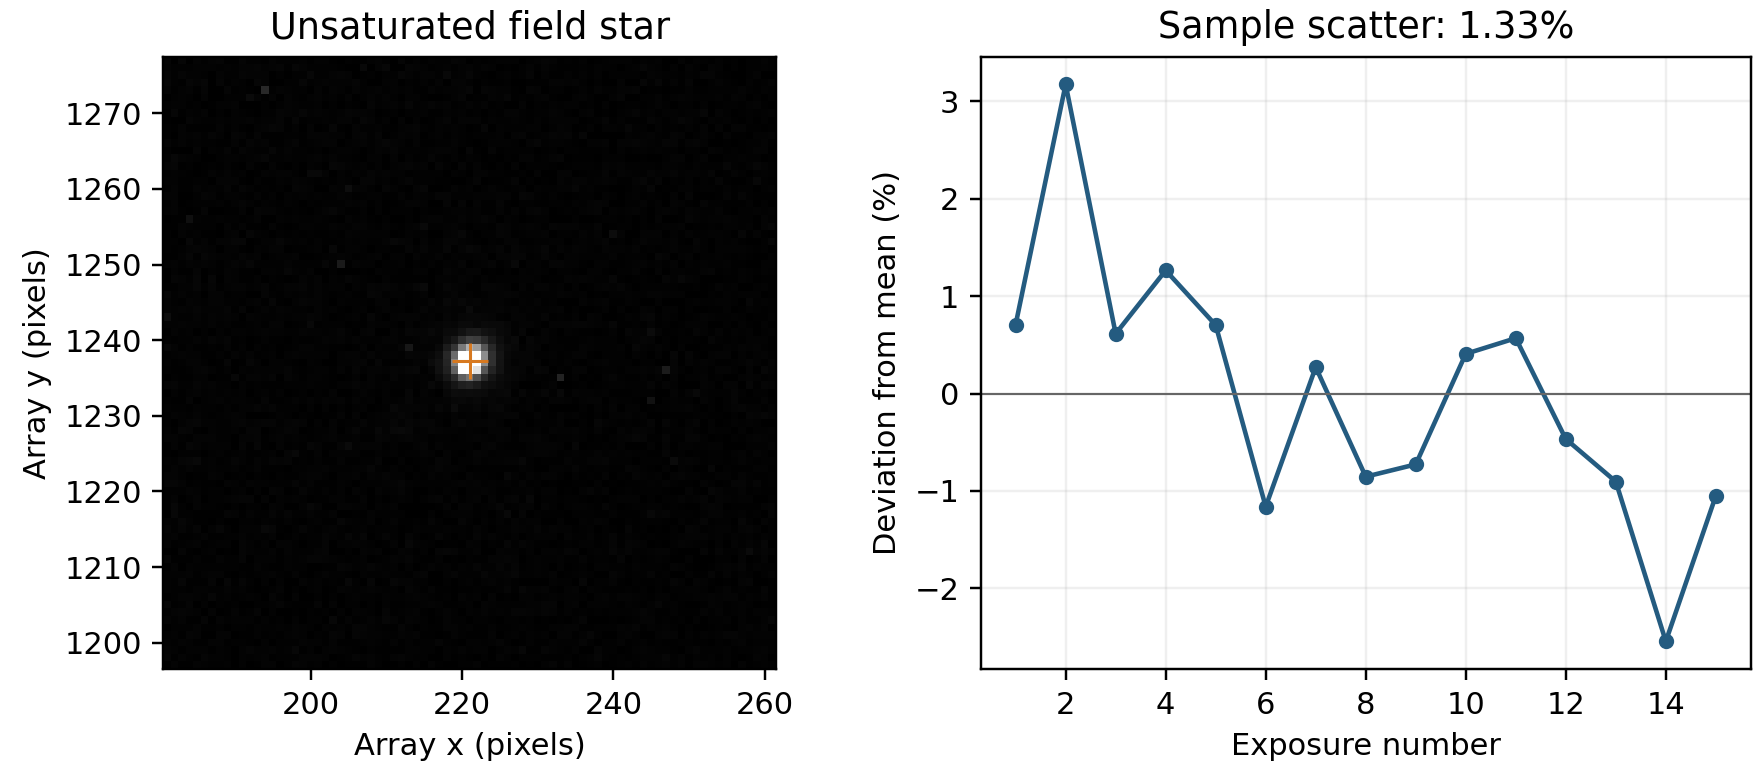

In [3]:
display(Image(filename=str(OUT/'unsaturated_field_star_check.png')))